# A cost-efficient Deep Learning model to emulate surface mass balance (SMB) over the Antartic Peninsula


In [ ]:
from datetime import datetime
from pathlib import Path

import numpy as np
import xarray as xr
from download_data import download_data

from super_resolution import rcm_emulator_entrypoint

%load_ext autoreload
%autoreload 2

[    INFO 2026-09-15 CEST 15:23:04.959 pid 43814,                        main.py, ln  33, in                  <module>()] Available datasets: CLIMATE_DT_SCENARIO_MIP_IFS_NEMO, CLIMATE_DT_SCENARIO_MIP_ICON, ERA5_REANALYSIS_HOURLY, ERA5_REANALYSIS_MONTHLY_MEANS, 4D_ANTARCTICA_SUBGLACIAL_LAKES, 4D_ANTARCTICA_SURFACE_MELT_MAPS, ANTARCTIC_OSCILLATION, BAS_OCEAN_MOORINGS, BED_MACHINE, C3S_SEA_ICE_CONCENTRATION, C3S_SEA_ICE_EDGE, GLORYS12V1, ICE_LINES_FRONTS_QUARTERLY, ICE_LINES_FRONTS_ANNUAL, ICE_LINES_FRONTS_MONTHLY, ICE_LINES_FRONTS_DAILY, ICE_LINES_FRONTS_ELIM_DAILY, ICE_LINES_FRONTS_ELIM_MONTHLY, ICE_LINES_FRONTS_ELIM_QUARTERLY, ICE_LINES_FRONTS_ELIM_ANNUAL, ITS_LIVE_ICE_VELOCITY, ITS_LIVE_BASAL_MELT, ICE_VELOCITY-S1-MONTHLY, ICE_VELOCITY-S1-YEARLY, POLAR_PLUS_ICE_SHELVES_BASAL_MELT, POLAR_PLUS_ICE_SHELVES_BASAL_MELT_TIMESERIES, POLAR_PLUS_ICE_SHELVES_CALVING_FRONT, POLAR_PLUS_ICE_SHELVES_MASS_BALANCE_COMPONENTS, RACMO, REMA_MOSAIC_1000, REMA_MOSAIC_100, REMA_GAPLESS_100, SOUTHERN_ANNULA

In [1]:
# query the api
import logging

from dtc_query_client import (
    ApiClient,
    DataDownloadRequest,
    DatasetID,
    Epsg4326PolygonJson,
    GenericApi,
    StateAndFateApi,
)
from dtc_query_client.helpers import wait_for_job
from shapely.geometry import MultiPolygon, Polygon, mapping
from unified_dashboard.query_api import get_api_config

# Set up logger for this module
logger = logging.getLogger(__name__)

ModuleNotFoundError: No module named 'dtc_query_client'

In [ ]:
import os

from dotenv import load_dotenv

load_dotenv()

if "DTC_API_AUTH_TOKEN" not in os.environ:
    raise EnvironmentError("DTC_API_AUTH_TOKEN must be set in the environment - create a .env file with the key.")

In [4]:
# Create an `ApiClient` for making requests
async with ApiClient(get_api_config()) as client:
    print("Starting job...")
    # Call the "run_summary_zarr_to_json" workflow
    res = await StateAndFateApi(client).run_summary_zarr_to_json(
        ice_shelf_id="thwaites",
    )
    # This should return the job ID of the started job
    job_id = res.job_id

    print("Waiting for job to complete...")
    # This line hangs until the job is complete, returning the final result.
    # (see also `iterate_job()` for an alternative that provides regular progress updates)
    result = await wait_for_job(client, job_id)

    print(f"Job completed with status {result.status}")
    print("Outputs:")
    print(result.outputs)

[    INFO 2026-09-15 CEST 15:23:23.552 pid 43814,                        auth.py, ln  49, in            get_user_token()] Using API token from environment variable for local development
[2026-09-15 15:23:23,552] INFO in unified_dashboard.auth: Using API token from environment variable for local development


Starting job...
Waiting for job to complete...
Job completed with status JobStatus.SUCCEEDED
Outputs:
{'timeseries-zarr-to-json-module': {'output_json': 'http://dtc-query-api-bucket.s3-website.gra.io.cloud.ovh.net/state_and_fate/summary_zarrs/thwaites_summary.json'}}


In [21]:
async with ApiClient() as client:
    # Start a job and get the job ID
    response = await GenericApi(client).dataset_overviews(dataset_id="ERA5_REANALYSIS_MONTHLY_MEANS")

    job_id = response.job_id
    print(f"Started job with ID {job_id}")

    # Wait for job to complete
    try:
        job_state = await wait_for_job(client, job_id)
    except RuntimeError as e:
        # Failed jobs will raise a RuntimeError
        print("Job has failed!")
        raise e

    # Job has completed! Print results
    print(f"Job completed successfully with status {job_state.status}.")
    output_url = job_state.outputs["timeseries-zarr-to-json-module"]["output_json"]
    print(f"Results URL: {output_url}")

ValidationError: 1 validation error for GenericApi.dataset_overviews
dataset_id
  Input should be a valid list [type=list_type, input_value='ERA5_REANALYSIS_MONTHLY_MEANS', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/list_type

In [13]:
async def run_data_download(
    dataset_id: DatasetID,
    start_time: datetime,
    end_time: datetime,
    epsg4326_polygon: Polygon | MultiPolygon,
    variables: list[str] | None = None,
) -> str:
    """Submit a data download job to the DTC Query API and return the resulting GeoZarr URL."""
    async with ApiClient(get_api_config()) as client:
        response = await GenericApi(client).download_data(
            DataDownloadRequest(
                dataset_id=dataset_id,
                start_time=start_time,
                end_time=end_time,
                epsg4326_polygon_json=Epsg4326PolygonJson.from_dict(mapping(epsg4326_polygon)),
                variables=variables,
            )
        )

        job_id = response.job_id
        logger.info("Data download job started with ID: %s", job_id)

        try:
            result = await wait_for_job(client, job_id)
        except RuntimeError:
            logger.exception("Data download job %s failed", job_id)
            raise

    return result.outputs["main"]["output_path"]

In [14]:
run_data_download(
    dataset_id="ERA5_MONTHLY",
    start_time=datetime(2020, 1, 1),
    end_time=datetime(2020, 12, 31),
    epsg4326_polygon=Polygon([(-10, 50), (-10, 60), (0, 60), (0, 50)]),
)

<coroutine object run_data_download at 0x73b328c03760>

Download the data from the DDM (Data Download Module):

In [2]:
START_DATE = datetime(2023, 1, 1)
END_DATE = datetime(2023, 3, 1)
OUTPUT_DIR = Path.cwd() / "local_data"

In [3]:
data_paths = download_data(START_DATE, END_DATE, OUTPUT_DIR)

gcm_path = data_paths["era5"]
rcm_path = data_paths["racmo"]

[    INFO 2026-08-21 CEST 17:14:13.203 pid 41330,                        main.py, ln  98, in             download_data()] Processing data download request dataset_id='ERA5_REANALYSIS_MONTHLY_MEANS' output_path=None output_parent_path=PosixPath('/home/ngaillard/super_resolution/scripts/local_data/ERA5') start_time=datetime.datetime(2023, 1, 1, 0, 0) end_time=datetime.datetime(2023, 3, 1, 0, 0) epsg4326_polygon=<POLYGON ((180 -90, 180 -60, -180 -60, -180 -90, 180 -90))> variables_to_download=['d2m', 'msl', 'sst', 'sp', 't2m', 'tp', 'u10', 'v10'] mask_data_to_polygon=False raw_download=False
[2026-08-21 17:14:13,203] INFO in data_download_module.main: Processing data download request dataset_id='ERA5_REANALYSIS_MONTHLY_MEANS' output_path=None output_parent_path=PosixPath('/home/ngaillard/super_resolution/scripts/local_data/ERA5') start_time=datetime.datetime(2023, 1, 1, 0, 0) end_time=datetime.datetime(2023, 3, 1, 0, 0) epsg4326_polygon=<POLYGON ((180 -90, 180 -60, -180 -60, -180 -90, 180

Call the emulator entrypoint

In [4]:
a = START_DATE.strftime("%Y-%m-%d")[:-3]
b = END_DATE.strftime("%Y-%m-%d")[:-3]
OUTPUT_PATH = OUTPUT_DIR / f"preds_{'_'.join([a, b])}.zarr"

In [1]:
rcm_emulator_entrypoint.main(
    gcm_zarr_path=gcm_path, rcm_zarr_path=rcm_path, output_zarr_path=OUTPUT_PATH, model_name="model_baseline_unet"
)

NameError: name 'rcm_emulator_entrypoint' is not defined

Read and plot the output

In [6]:
preds_ds = xr.open_zarr(OUTPUT_PATH)

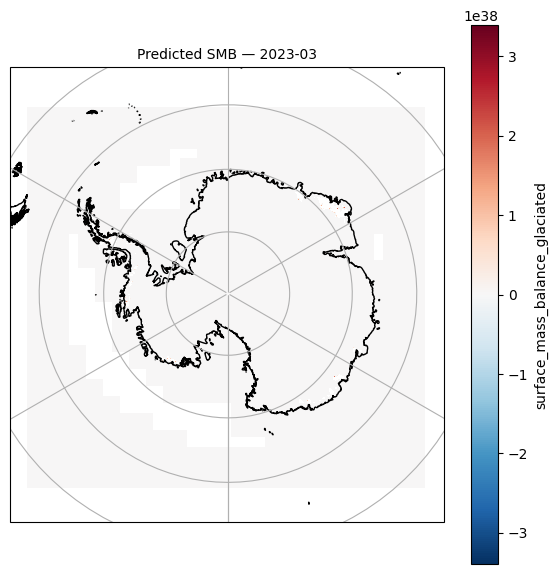

In [ ]:
import cartopy.crs as ccrs
import xarray as xr
from matplotlib import pyplot as plt

time_idx = 2

actual_time = preds_ds.time[time_idx].to_numpy()
actual_time_str = str(actual_time)[:7]

map_proj = ccrs.SouthPolarStereo(central_longitude=0.0)

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": map_proj})

preds_ds.isel(time=time_idx).surface_mass_balance_glaciated.plot(
    ax=ax, x="x", y="y", transform=ccrs.SouthPolarStereo(), add_colorbar=True, cmap="RdBu_r"
)

ax.coastlines("10m")
ax.gridlines(draw_labels=False)
ax.set_title(f"Predicted SMB — {actual_time_str}", fontsize=10)
plt.show()

## Timeseries

In [ ]:
def create_lower_target(
    target_dataset: xr.DataArray,  # target dataset
    region: str = "Larsen",  # region of interest
    nx: int = 64,  # new size of x dimension
    ny: int = 64,  # new size of y dimension
    print_: bool = True,
) -> xr.DataArray:
    """TODO: write me."""
    max_y = nx * 35 * 1000
    max_x = ny * 35 * 1000

    min_x_res = target_dataset.x.min().to_numpy()
    min_y_res = target_dataset.y.min().to_numpy()

    max_x_res = target_dataset.x.max().to_numpy()
    max_y_res = target_dataset.y.max().to_numpy()

    if region == "Larsen":
        df_lower = target_dataset.where(target_dataset.y >= 0, drop=True)
        df_lower = df_lower.where(df_lower.y < max_y, drop=True)
        df_lower = df_lower.where(df_lower.x < min_x_res + max_x, drop=True)

    if region == "Lower peninsula":
        max_x = (nx / 2) * 35 * 1000
        max_y = ny * 35 * 1000
        # df = cutBoundaries(target_dataset, max_x, max_y, lowerHalf=True) TODO - add cutBoundaries back in

    if region == "Amundsen":
        df_lower = target_dataset.where(target_dataset.y <= min_y_res + 1.5 * max_y, drop=True)
        df_lower = df_lower.where(df_lower.y > min_y_res + 0.5 * max_y, drop=True)
        df_lower = df_lower.where(df_lower.x < min_x_res + max_x, drop=True)

    if region == "Wilkes":
        df_lower = target_dataset.where(target_dataset.x > max_x_res - max_x, drop=True)
        df_lower = df_lower.where(df_lower.y <= min_y_res + 1.5 * max_y, drop=True)
        df_lower = df_lower.where(df_lower.y > min_y_res + 0.5 * max_y, drop=True)

    if region == "Maud":
        df_lower = target_dataset.where(target_dataset.y > max_y_res - max_y, drop=True)
        df_lower = df_lower.where(df_lower.x >= max_x_res - 1.5 * max_x, drop=True)
        df_lower = df_lower.where(df_lower.x < max_x_res - 0.5 * max_x, drop=True)
    if print_:
        print("New target dimensions:", df_lower.dims)
    return df_lower


"""create_lower_input: creates a subset of the input domain, cut to new dimensions x and y
"""


def _create_lower_input(
    uprcm: xr.DataArray,
    region: str = "Larsen",  # region of interest
    nx: int = 48,  # new size of x dimension
    ny: int = 25,  # new size of y dimension  # noqa: ARG001 - TODO: should ny be used?
    print_: bool = True,
) -> xr.DataArray:
    if region == "Lower peninsula":
        max_x = (nx / 2) * 68 * 1000
        # max_y = (ny) * 206 * 1000 - TODO: should max_y be used?

        df_lower = uprcm.where(uprcm.x < max_x, drop=True)
        df_lower = df_lower.where(-max_x <= df_lower.x, drop=True)

    if region == "Larsen":
        min_x = uprcm.x.min().to_numpy()
        df_lower = uprcm.where(uprcm.x < min_x + (nx * 68 * 1000), drop=True)

    if region == "Amundsen":  # same region as Larsen
        min_x = uprcm.x.min().to_numpy()
        df_lower = uprcm.where(uprcm.x < min_x + (nx * 68 * 1000), drop=True)

    if region == "Wilkes":  # same region as Larsen
        max_x = uprcm.x.max().to_numpy()
        df_lower = uprcm.where(uprcm.x > max_x - (nx * 68 * 1000), drop=True)

    if region == "Maud":  # same region as lower peninsula
        max_x = (nx / 2) * 68 * 1000
        # max_y = (ny) * 206 * 1000 - TODO: should max_y be used?

        df_lower = uprcm.where(uprcm.x < max_x, drop=True)
        df_lower = df_lower.where(-max_x <= df_lower.x, drop=True)

    if print_:
        print("New dimensions:", df_lower.dims)

    return df_lower


# create mask
def create_mask(true_smb: np.ndarray, onechannel: bool = True) -> np.ndarray:
    """TODO: write me."""
    array_smb = np.array(true_smb)
    if onechannel:
        dimx = true_smb.shape[1]
        dimy = true_smb.shape[0]
    mask = np.empty((dimy, dimx))
    for y in range(dimy):
        for x in range(dimx):
            pixel_smb = array_smb[y, x, 0]
            if not np.any(pixel_smb):  # check if all zeros (then on sea)
                mask[y, x] = 0
            else:
                mask[y, x] = 1
    return mask

In [ ]:
points_rcm = (
    {"x": 16, "y": 32},
    {"x": 27, "y": 22},
    {"x": 31, "y": 26},
    {"x": 52, "y": 17},
)

labels = [
    r"$\mathrm{\operatorname{\hat{F}_{P}(UPRCM)}}$",
    r"$\mathrm{\operatorname{\hat{F}_{P}(GCM)}}$",
    r"$\mathrm{\operatorname{\hat{F}_{I}(GCM)}}$",
    "RCM Truth",
]
# TODO - import these datasets:
# dfPixels = plotTimeseries3Models(
#     preds1=preds_Larsen_NRMSE,
#     preds2=preds_Larsen_NRMSE_GCM,
#     preds3=preds_Larsen_NRMSE_GCM_tr,
#     true_smb=true_smb_Larsen_NRMSE,
#     train_set=train_set_GCM,
#     target_dataset=target_dataset,
#     points_rcm=points_rcm,
#     region=REGION,
#     figsize=(20, 18),
#     labels=labels,
#     fontsize=24,
# )
# plt.savefig("timeseries.pdf")